# Project 2 — House Price Exploratory Data Analysis

## Introduction

The objective of this project is to explore the California Housing dataset and investigate how household income, housing characteristics, population measures, and geographic location relate to recorded house values.

The analysis includes descriptive statistics, histograms, boxplots, cumulative distribution analysis, correlation analysis, linear regression, and comparisons across income groups. The goal is to identify meaningful patterns, assess potential data-quality issues, and understand the limitations of the dataset before any predictive modeling.

## Dataset Description

The California Housing dataset contains 20,640 observations and eight input features describing census block groups in California. The target variable, `MedHouseVal`, represents the median house value for each block group and is measured in units of $100,000.

The input features are:

- `MedInc`: Median household income.
- `HouseAge`: Median house age.
- `AveRooms`: Average number of rooms per household.
- `AveBedrms`: Average number of bedrooms per household.
- `Population`: Census block-group population.
- `AveOccup`: Average household occupancy.
- `Latitude`: Geographic latitude.
- `Longitude`: Geographic longitude.

These observations describe census block groups rather than individual houses. Therefore, the results should be interpreted at the block-group level.

In [2]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dataset = fetch_california_housing()

In [4]:
df_data = pd.DataFrame(dataset.data, columns=dataset.feature_names)

In [5]:
df_target = pd.DataFrame(dataset.target, columns=['MedHouseVal'])

In [6]:
df = pd.concat([df_data, df_target], axis=1)

In [7]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [8]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### Descriptive Analysis of the Target Variable (`MedHouseVal`)

The target variable, `MedHouseVal`, represents the median house value for each California census block group, measured in units of $100,000.

**Key descriptive statistics:**

- **Mean:** 2.0686 (approximately $206,860)

- **Median:** 1.7970 (approximately $179,700)

- **Standard deviation:** 1.1540 (approximately $115,400)

- **Minimum:** 0.14999 (approximately $15,000)

- **Maximum:** 5.00001 (approximately $500,001)

- **Range:** 4.85002 (approximately $485,002)

- **First quartile (Q1):** 1.1960 (approximately $119,600)

- **Third quartile (Q3):** 2.6472 (approximately $264,720)

- **Interquartile range (IQR):** 1.4512 (approximately $145,120)

**Interpretation**

The mean is higher than the median, suggesting a positively skewed (right-skewed) distribution. A relatively small number of high-value areas may pull the mean upward.

The middle 50% of observations have recorded median house values between approximately $119,600 

and $264,700.

The maximum value is constrained by the dataset's upper price cap. Therefore, observations near $500,000 should be interpreted cautiously because the dataset does not distinguish their underlying values precisely.

In [10]:
df.shape

(20640, 9)

In [11]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [12]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [13]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.nunique()

MedInc         12928
HouseAge          52
AveRooms       19392
AveBedrms      14233
Population      3888
AveOccup       18841
Latitude         862
Longitude        844
MedHouseVal     3842
dtype: int64

In [16]:
df[['Latitude', 'Longitude']].drop_duplicates().shape[0]

12590

In [17]:
df['Location_ID'] = df.groupby( ['Latitude', 'Longitude'], dropna=False).ngroup() + 1

In [18]:
df.sort_values(by="Location_ID")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Location_ID
14762,1.2667,7.0,3.326241,1.053191,1187.0,4.209220,32.54,-117.04,0.675,1
14784,3.9583,8.0,5.550552,1.033985,4797.0,4.075616,32.55,-117.09,1.444,2
14761,1.4384,5.0,3.774005,1.100703,3284.0,3.845433,32.55,-117.06,1.088,3
14757,1.6348,15.0,3.404321,1.000000,2511.0,3.875000,32.55,-117.04,0.932,4
14790,2.9286,20.0,4.507143,1.217857,1819.0,3.248214,32.56,-117.12,2.577,5
...,...,...,...,...,...,...,...,...,...,...
18824,1.7400,28.0,6.158892,1.217201,1908.0,2.781341,41.86,-121.93,0.440,12586
1864,3.1300,18.0,5.829457,1.383721,660.0,2.558140,41.88,-123.83,1.167,12587
1860,2.1336,19.0,5.893993,1.144876,841.0,2.971731,41.92,-124.16,0.750,12588
1859,2.2750,21.0,5.457490,1.170040,1208.0,2.445344,41.95,-124.14,1.224,12589


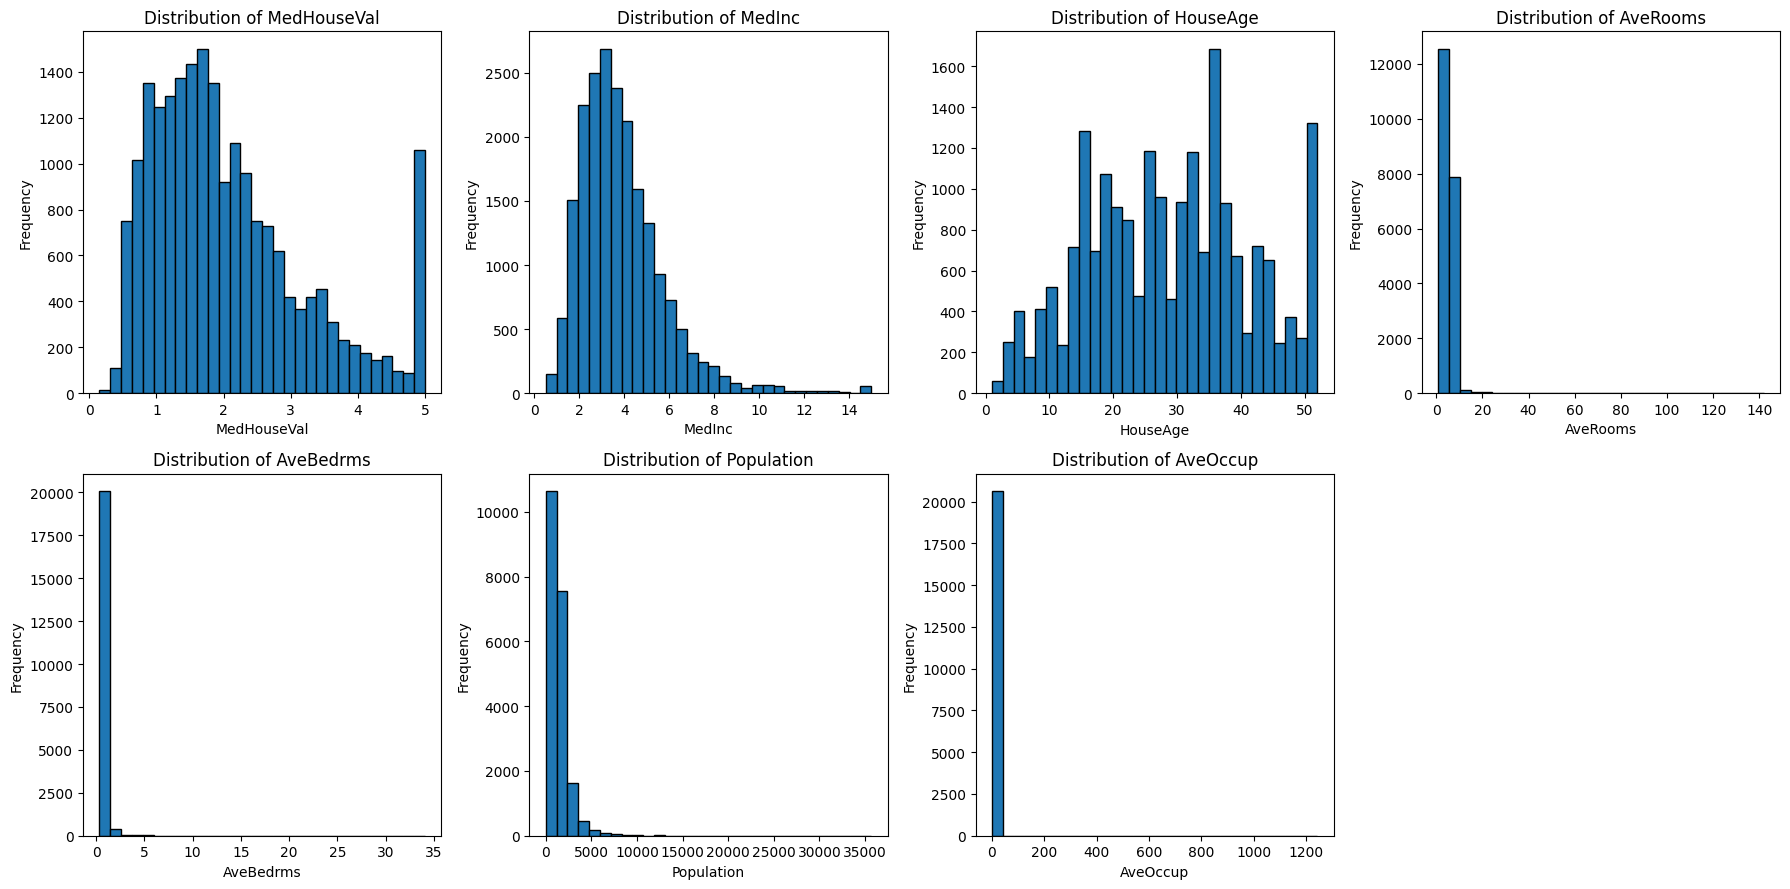

In [19]:
columns = [
    'MedHouseVal', 'MedInc', 'HouseAge',
    'AveRooms', 'AveBedrms', 'Population', 'AveOccup'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(columns):
    axes[i].hist(df[col], bins=30, edgecolor='black')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Feature Distribution Analysis (Histograms)

**`MedHouseVal` — Target Variable**

The target distribution is positively skewed, with many observations concentrated in the lower-to-middle value range, approximately $100,000 to $250,000.

A pronounced spike appears near the upper boundary of $500,000. This reflects the dataset's top-coding: values above the cap are recorded at approximately this limit, so the most expensive areas cannot be distinguished precisely.

**`MedInc` — Median Household Income**

`MedInc` is right-skewed. Many observations fall between approximately 2 and 4, corresponding to median annual household incomes of roughly $20,000–$40,000. Values above 8 are relatively uncommon.

**`HouseAge` — Median House Age**

The distribution contains a noticeable spike at 52 years. This indicates that house ages above this threshold are top-coded at 52 rather than recorded at their exact ages.

**Structural and Population Features**

`AveRooms`, `AveBedrms`, `Population`, and `AveOccup` exhibit strongly right-skewed distributions. Most observations are concentrated at relatively low values, while a smaller number of extreme observations produce long right tails.

In [20]:
(df['MedHouseVal'] > 5.0).sum()

np.int64(965)

In [21]:
df[df['MedHouseVal'] > 5.0]

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Location_ID
89,1.2434,52.0,2.929412,0.917647,396.0,4.658824,37.80,-122.27,5.00001,9397
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,9569
493,7.8521,52.0,7.794393,1.051402,517.0,2.415888,37.86,-122.24,5.00001,9546
494,9.3959,52.0,7.512097,0.955645,1366.0,2.754032,37.85,-122.24,5.00001,9526
509,7.8772,52.0,8.282548,1.049861,947.0,2.623269,37.83,-122.23,5.00001,9485
...,...,...,...,...,...,...,...,...,...,...
20422,5.1457,35.0,6.958333,1.217593,576.0,2.666667,34.14,-118.90,5.00001,4581
20426,10.0472,11.0,9.890756,1.159664,415.0,3.487395,34.18,-118.69,5.00001,4939
20427,8.6499,4.0,7.236059,1.032528,5495.0,2.553439,34.19,-118.80,5.00001,5011
20436,12.5420,10.0,9.873315,1.102426,1179.0,3.177898,34.21,-118.69,5.00001,5133


In [22]:
(df['MedHouseVal'] == 5.0).mean() * 100

np.float64(0.1308139534883721)

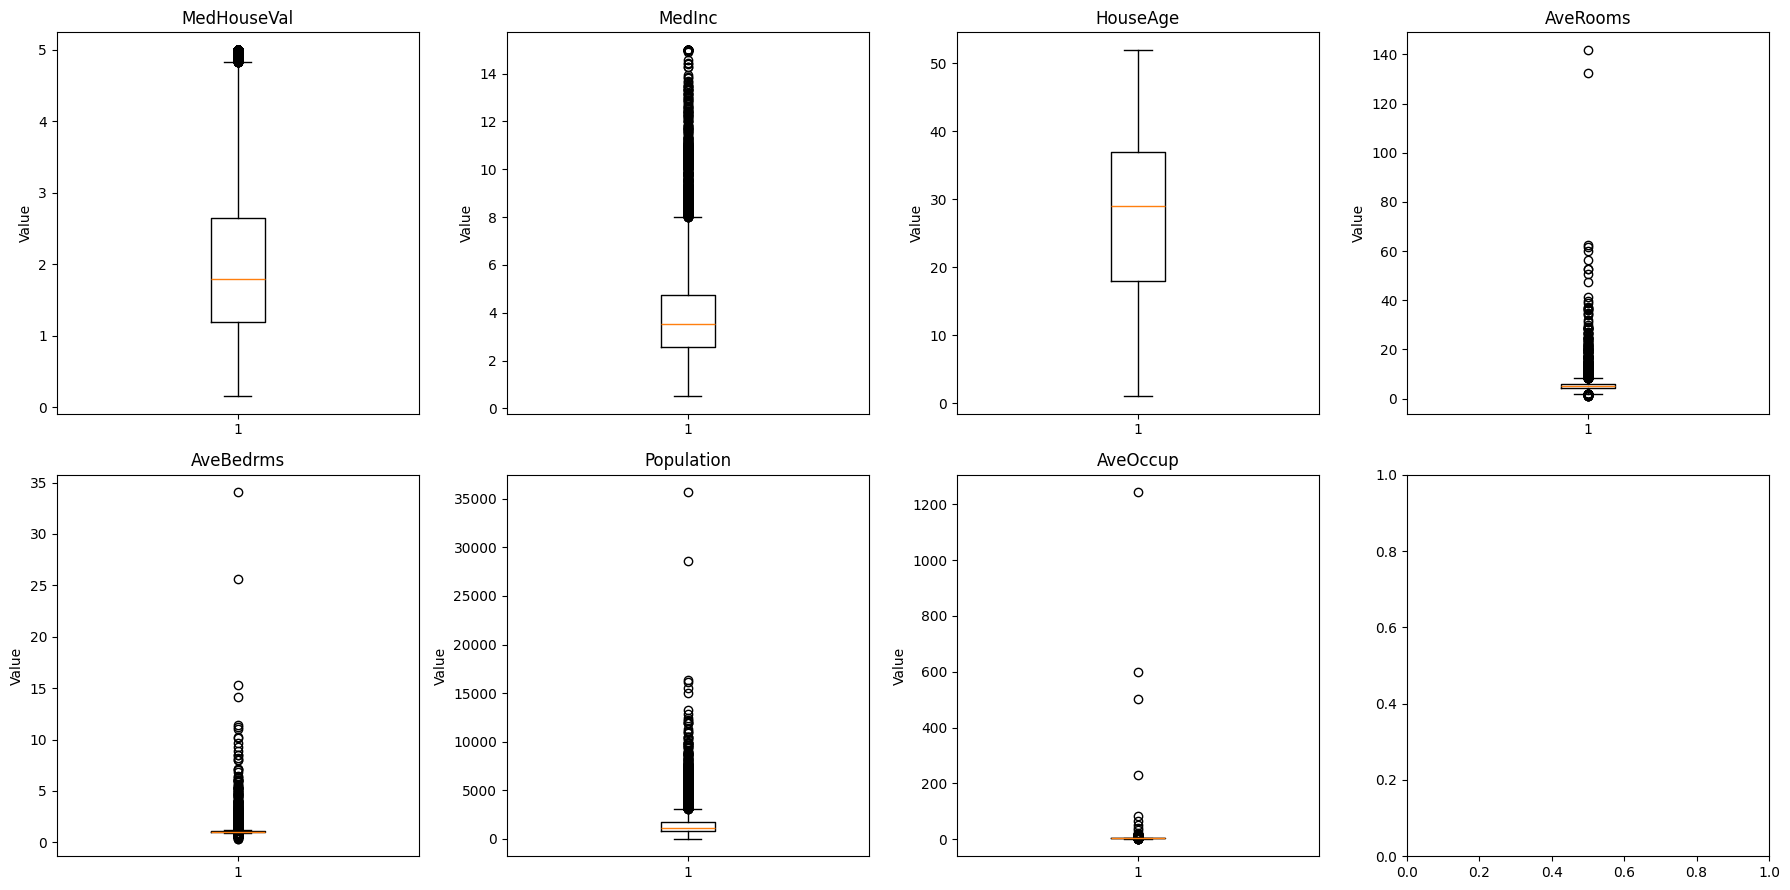

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(columns):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)
    axes[i].set_ylabel('Value')

plt.tight_layout()
plt.show()

### Outlier and Spread Analysis (Boxplots)

The boxplots reveal potential outliers in several numerical features.

**Potential Extreme Outliers**

- **`AveRooms`:** Most observations are concentrated around 4–6 average rooms, but some values exceed 140. These unusually large values may reflect atypical census block groups and require further investigation.
- **`AveOccup`:** The median is approximately 2.8 occupants per household, while some observations exceed 1,200. These extreme values may represent unusual block-group characteristics or data anomalies.
- **`Population`:** Although the central 50% of observations covers a much smaller range, some census block groups have populations approaching 35,000.

**Features Requiring Contextual Interpretation**

- **`MedInc`:** Values beyond the conventional boxplot whiskers may represent genuinely affluent areas rather than data-entry errors.
- **`HouseAge`:** No observations may be flagged as outliers under the 1.5 × IQR rule. However, the 52-year upper cap limits the interpretation of this result.

**Preprocessing Implications**

Outliers should not be removed automatically. Their plausibility and influence should be investigated before deciding how to handle them.

Extreme values in `AveRooms`, `AveBedrms`, and `AveOccup` may affect scaling and model fitting. Robust scaling or suitable transformations may be considered during preprocessing, depending on the selected model and validation results.

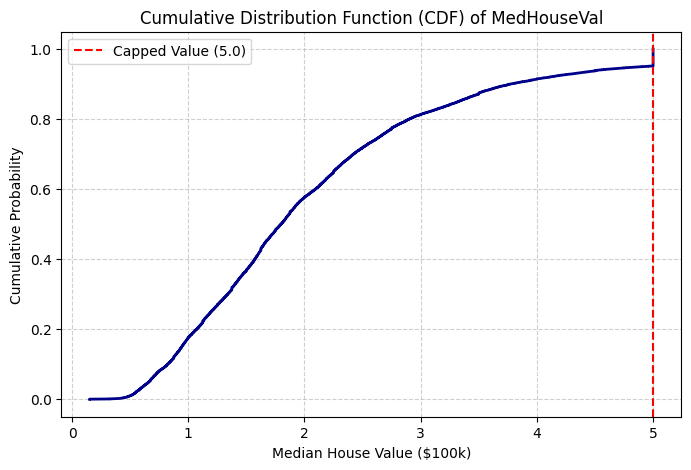

In [24]:
# Cumulative Distribution
plt.figure(figsize=(8, 5))
sorted_data = np.sort(df['MedHouseVal'])
yvals = np.arange(len(sorted_data)) / float(len(sorted_data) - 1)

plt.plot(sorted_data, yvals, color='darkblue', linewidth=2)
plt.title('Cumulative Distribution Function (CDF) of MedHouseVal')
plt.xlabel('Median House Value ($100k)')
plt.ylabel('Cumulative Probability')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=5.0, color='red', linestyle='--', label='Capped Value (5.0)')
plt.legend()
plt.show()

### Cumulative Distribution Analysis of House Values

The cumulative distribution function (CDF) shows the proportion of observations with recorded median house values less than or equal to a given value.

**Concentration in the Lower-to-Middle Value Range**

The CDF rises relatively quickly between approximately 1.0 and 2.5, indicating that many observations fall within this range.

- **Median (50th percentile):** Approximately 1.797, or $179,700.
- **Third quartile (75th percentile):** Approximately 2.65, or $265,000.

Thus, approximately 50% of observations have recorded values at or below $179,700, and approximately 75% are at or below $265,000.

**Upper-Value Tail and Top-Coding**

The CDF increases more gradually across much of the range from 3.0 to 4.9, indicating a smaller concentration of observations at higher recorded values.

The sharp final increase near 5.0 reflects the dataset's upper price cap. Observations at this boundary may have underlying values above $500,000, but their exact values are not preserved.

**Implications for Modeling**

The upper cap limits the information available about the most expensive areas. Consequently, models trained on this target may not fully capture differences among high-value locations.

In [25]:
# Correlation Matrix
features_corr = df.drop(columns=['Location_ID']).corr()

# Top 5 features with highest corr
top_5_corr = features_corr['MedHouseVal'].drop('MedHouseVal').abs().sort_values(ascending=False).head(5)
print("Top 5 Features with Highest Absolute Correlation with MedHouseVal:")
print(features_corr.loc[top_5_corr.index, 'MedHouseVal'])

Top 5 Features with Highest Absolute Correlation with MedHouseVal:
MedInc       0.688075
AveRooms     0.151948
Latitude    -0.144160
HouseAge     0.105623
AveBedrms   -0.046701
Name: MedHouseVal, dtype: float64


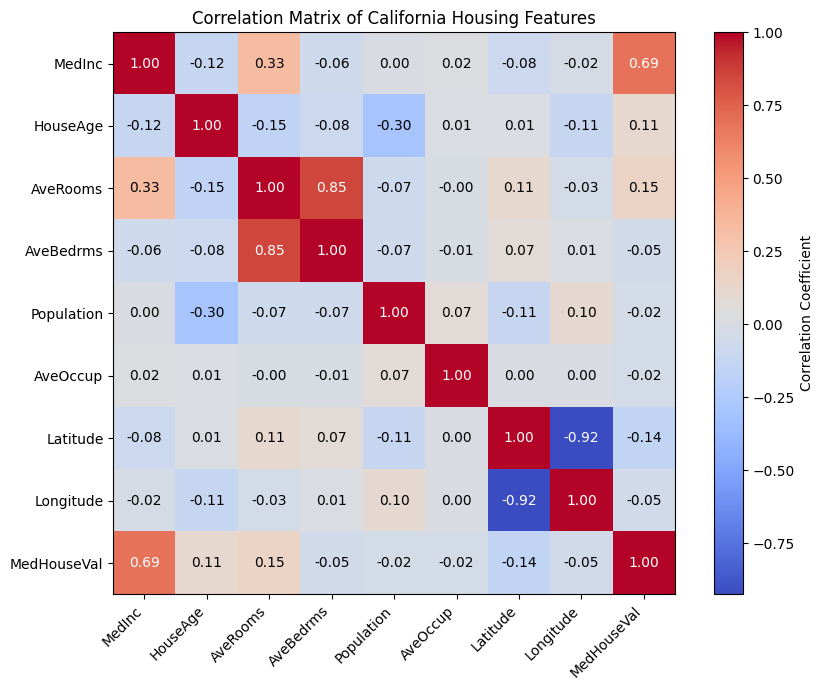

In [26]:
plt.figure(figsize=(9, 7))
plt.imshow(features_corr, cmap='coolwarm')
plt.colorbar(label='Correlation Coefficient')
plt.xticks(range(len(features_corr.columns)), features_corr.columns, rotation=45, ha='right')
plt.yticks(range(len(features_corr.columns)), features_corr.columns)
#show numbers in matrix
for i in range(len(features_corr.columns)):
    for j in range(len(features_corr.columns)):
        plt.text(j, i, f"{features_corr.iloc[i, j]:.2f}", ha='center', va='center', 
                 color='white' if abs(features_corr.iloc[i, j]) > 0.5 else 'black')

plt.title('Correlation Matrix of California Housing Features')
plt.tight_layout()
plt.show()

### Correlation Analysis

Pearson correlation measures the strength and direction of a linear relationship between two numerical variables. The correlations between the input features and `MedHouseVal` are summarized below.

| Feature | Pearson correlation | Interpretation |
|---|---:|---|
| `MedInc` | +0.6881 | Strongest positive linear association |
| `AveRooms` | +0.1519 | Weak positive association |
| `Latitude` | −0.1442 | Weak negative association |
| `HouseAge` | +0.1056 | Weak positive association |
| `AveBedrms` | −0.0467 | Very weak negative association |
| `Longitude` | −0.0460 | Very weak negative association |
| `Population` | −0.0247 | Negligible linear association |
| `AveOccup` | −0.0237 | Negligible linear association |

**Key Findings**

**1. Median Income (`MedInc`)**

`MedInc` has the strongest individual linear association with house values, with a correlation of approximately +0.69. Census block groups with higher median incomes tend to have higher recorded median house values.

**2. Average Rooms (`AveRooms`)**

`AveRooms` has a weak positive association with house values. However, average room count is not a direct measure of floor area, so its relationship with price should be interpreted cautiously.

**3. Geographic Location (`Latitude` and `Longitude`)**

The individual linear correlations of latitude and longitude are weak. However, this does not rule out important spatial patterns. House values may vary nonlinearly with location, including proximity to coastlines and major metropolitan areas.

**4. House Age (`HouseAge`)**

The weak positive correlation indicates that older census block groups tend to have slightly higher recorded values in this dataset. This does not imply that increasing the age of an individual house causes its value to rise.

**Relationships Among Predictors**

`AveRooms` and `AveBedrms` are strongly correlated with each other (approximately r = 0.85 in the supplied analysis). This may introduce multicollinearity in linear regression and make individual coefficients harder to interpret.

**Conclusion**

`MedInc` is the strongest individual linear correlate of `MedHouseVal`. Geographic coordinates may provide additional predictive information through nonlinear spatial patterns. Correlation alone does not establish causation or fully determine a feature's predictive value.

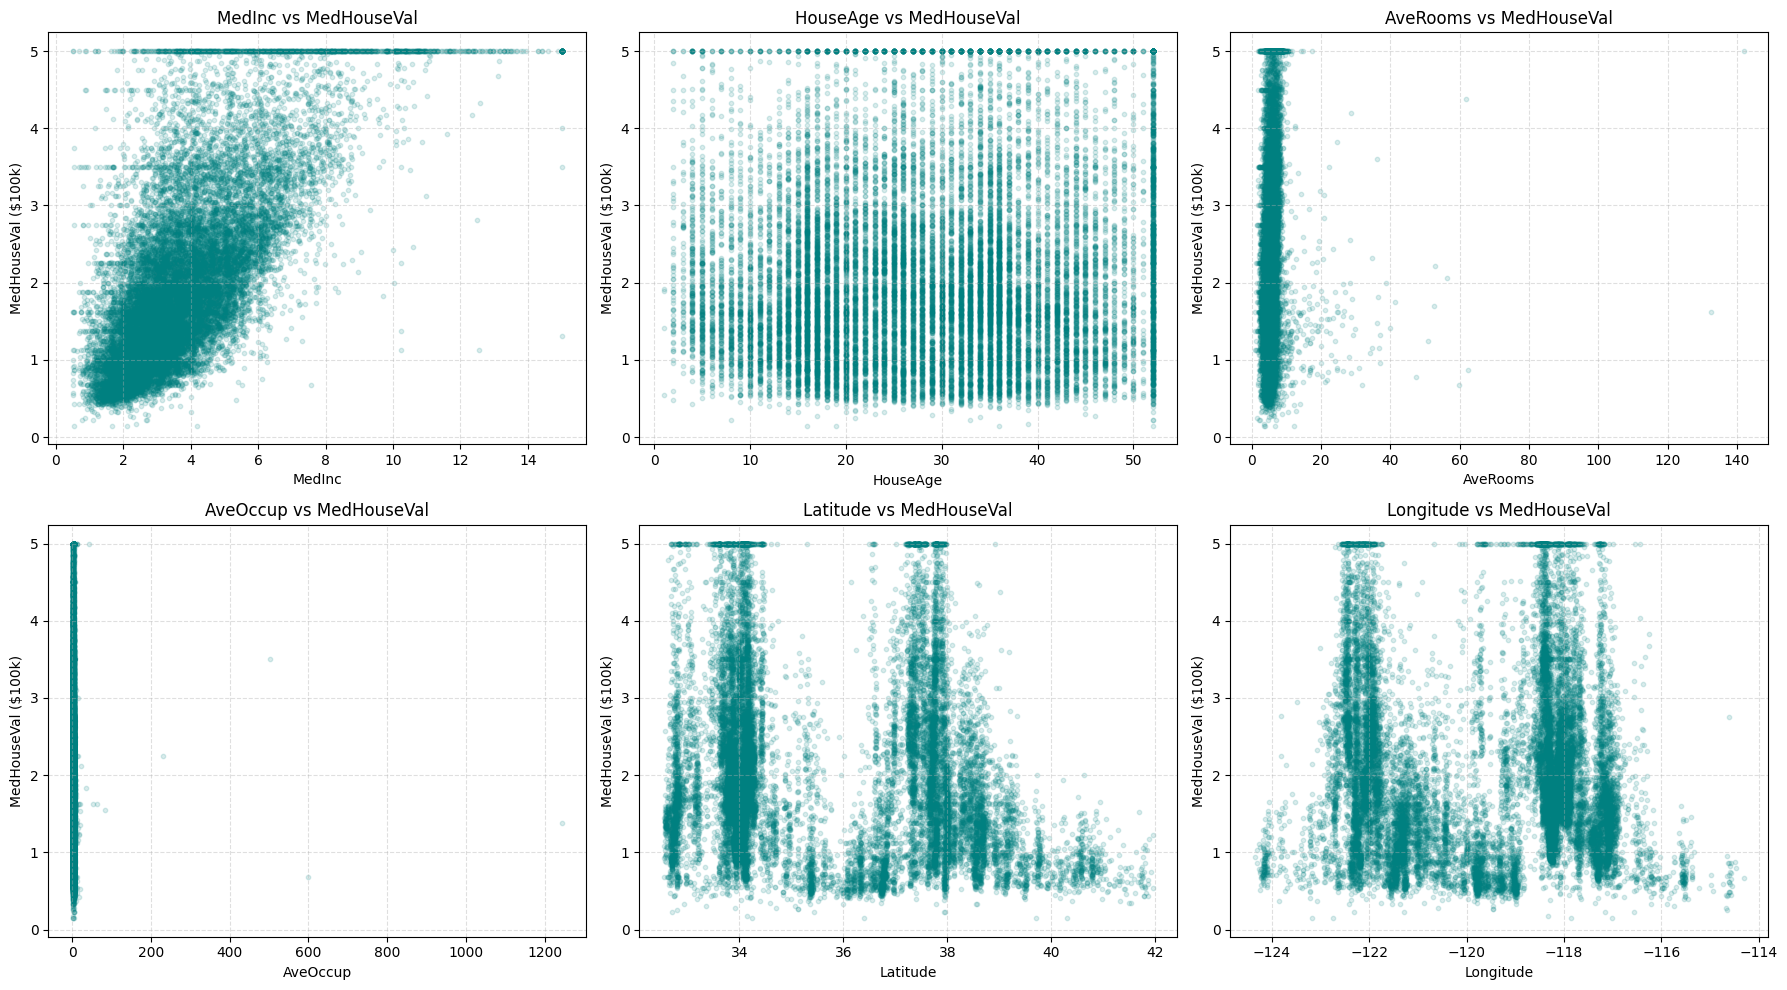

In [27]:
# Scatter plot of important features VS Median of House Vals
features_to_plot = ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    axes[i].scatter(df[col], df['MedHouseVal'], alpha=0.15, color='teal', s=10)
    axes[i].set_title(f'{col} vs MedHouseVal')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('MedHouseVal ($100k)')
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

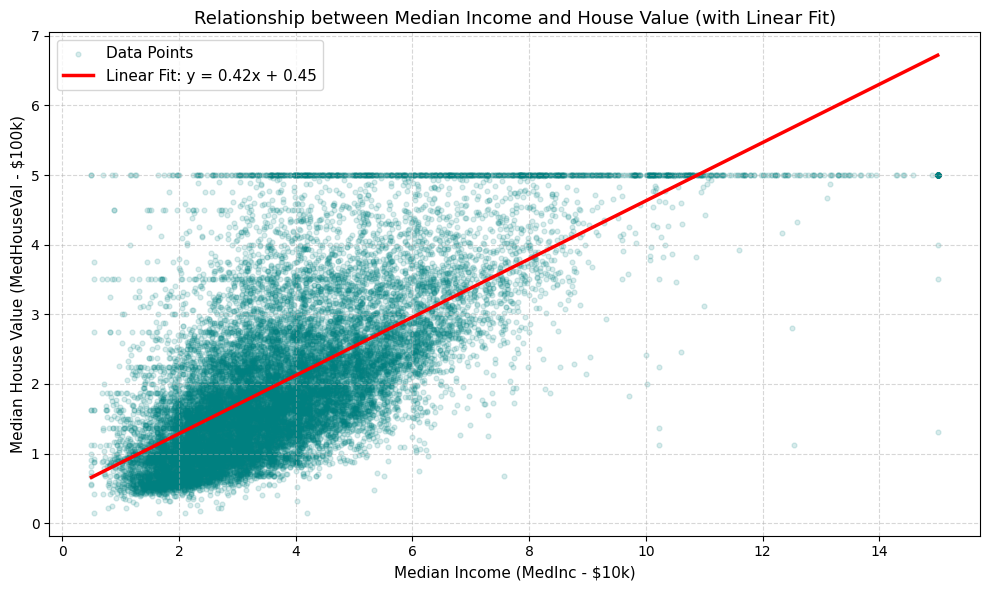

In [28]:
# Extraction of 2 cols data
x = df['MedInc']
y = df['MedHouseVal']

# calculate m,b with 1st degree linear regression
m, b = np.polyfit(x, y, deg=1)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.15, color='teal', s=12, label='Data Points')

# draw linear regression line
x_vals = np.linspace(x.min(), x.max(), 100)
plt.plot(x_vals, m * x_vals + b, color='red', linewidth=2.5, 
         label=f'Linear Fit: y = {m:.2f}x + {b:.2f}')

plt.title('Relationship between Median Income and House Value (with Linear Fit)', fontsize=13)
plt.xlabel('Median Income (MedInc - $10k)', fontsize=11)
plt.ylabel('Median House Value (MedHouseVal - $100k)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

### Linear Regression Analysis: `MedInc` vs. `MedHouseVal`

The fitted regression line has a positive slope of approximately 0.42. Given the dataset's units, a one-unit increase in `MedInc` corresponds to an estimated increase of approximately 0.42 in `MedHouseVal`, or roughly $42,000, on average in this simple linear fit.

The positive slope is consistent with the Pearson correlation of approximately +0.688 between median income and recorded median house value. This indicates that income is a useful single-feature variable for describing the overall trend.

**Limitations**

This relationship is associative rather than causal. Other factors, particularly geographic location, may also contribute to differences in house values.

At high income levels, the target's upper cap near $500,000 compresses recorded values. As a result, the observed relationship may not accurately represent the underlying relationship among the most expensive areas.

In [29]:
print(pd.cut(df['MedInc']*100 , bins=5))

0        (629.998, 920.002]
1        (629.998, 920.002]
2        (629.998, 920.002]
3        (339.994, 629.998]
4        (339.994, 629.998]
                ...        
20635      (48.54, 339.994]
20636      (48.54, 339.994]
20637      (48.54, 339.994]
20638      (48.54, 339.994]
20639      (48.54, 339.994]
Name: MedInc, Length: 20640, dtype: category
Categories (5, interval[float64, right]): [(48.54, 339.994] < (339.994, 629.998] < (629.998, 920.002] < (920.002, 1210.006] < (1210.006, 1500.01]]


In [30]:
df['divide_inc'] = pd.cut(df['MedInc']*100 , bins=5)

In [32]:
median_prices = df.groupby(
    'divide_inc',
    observed=True
)['MedHouseVal'].median()

print(median_prices*100)

divide_inc
(48.54, 339.994]       127.300
(339.994, 629.998]     216.600
(629.998, 920.002]     367.400
(920.002, 1210.006]    500.001
(1210.006, 1500.01]    500.001
Name: MedHouseVal, dtype: float64


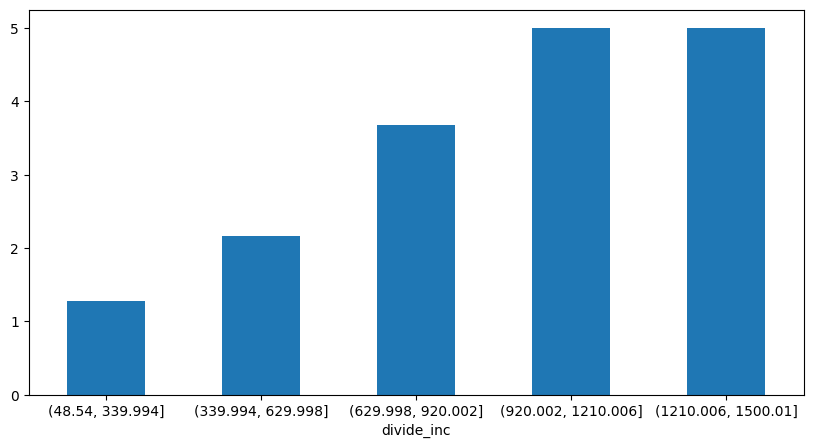

In [33]:
median_prices.plot(kind='bar', figsize=(10, 5))
plt.tick_params(axis='x', rotation=0)
plt.show()

### House Values Across Median Income Groups

The dataset was divided into five income intervals based on `MedInc`. The median `MedHouseVal` was then calculated for each group to compare recorded house values across income levels.

This grouped comparison helps reveal whether census block groups with higher median household incomes also tend to have higher median house values.

**Interpretation**

Compare the median house value across the five income groups. An increasing pattern would indicate that higher-income groups generally have higher recorded house values.

This relationship is consistent with the positive correlation between `MedInc` and `MedHouseVal`. However, the grouped comparison is descriptive and does not establish causation.

Note that `MedInc` is expressed in units of $10,000

, whereas MedHouseVal is expressed in units of $100,000. The units should be clearly labeled when presenting the results.

## Final EDA Summary

The exploratory analysis reveals several important patterns in the California Housing dataset.

1. **Target distribution:** `MedHouseVal` has a mean of approximately 2.0686 and a median of 1.7970, suggesting a positively skewed distribution. The middle 50% of observations range from approximately 1.1960 to 2.6472.

2. **Upper price cap:** The target is capped near $500,000. This limits the ability to distinguish the most expensive areas and should be considered when interpreting distributions and regression results.

3. **Feature distributions:** `MedInc` is right-skewed, `HouseAge` has a noticeable upper-bound spike at 52 years, and `AveRooms`, `AveBedrms`, `Population`, and `AveOccup` contain long right tails.

4. **Potential outliers:** Boxplots identify extreme values in several features, particularly `AveRooms`, `AveOccup`, and `Population`. These values require contextual investigation rather than automatic removal.

5. **Correlation patterns:** `MedInc` has the strongest Pearson correlation with `MedHouseVal` (approximately +0.6881). The individual linear correlations of latitude and longitude are weak, but geographic relationships may be nonlinear.

6. **Income-group comparison:** Comparing median house values across `MedInc` intervals provides a clear descriptive view of how recorded house values vary with household income. The actual group medians should be used to state the observed trend.

7. **Regression relationship:** The simple linear regression of `MedInc` against `MedHouseVal` shows a positive relationship. However, this association is not causal, and the target's upper cap limits interpretation at the high-value end.

## Overall Conclusion

Median household income is the strongest individual linear correlate of recorded median house value in this exploratory analysis. Geographic location and nonlinear relationships may provide additional information that simple correlation coefficients cannot capture.

The findings provide a useful foundation for further feature engineering and predictive modeling. However, potential outliers, the census block-group level of aggregation, and the target's upper price cap should be considered before drawing broader conclusions or building machine-learning models.